In [1]:
!pip -q install ucimlrepo

In [2]:
import os, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, classification_report, confusion_matrix
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Create folders where project outputs will be saved.
PROJECT_DIR = "/content/Student_Performance_Project"
GRAPH_DIR = os.path.join(PROJECT_DIR, "Graphs")
REPORT_DIR = os.path.join(PROJECT_DIR, "Reports")
os.makedirs(GRAPH_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

print("Setup complete.")

Setup complete.


In [3]:
# 1. Distribution of final grades
plt.figure(figsize=(8, 5))
plt.hist(df["G3"], bins=20, edgecolor="black")
plt.title("Distribution of Students' Final Grades (G3)")
plt.xlabel("Final grade (0–20)")
plt.ylabel("Number of students")
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, "01_grade_distribution.png"), dpi=150)
plt.show()

NameError: name 'df' is not defined

<Figure size 800x500 with 0 Axes>

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
plt.hist(df["G3"])

plt.title("Student Final Grade Distribution")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.show()

NameError: name 'df' is not defined

In [6]:
plt.hist(df["G3"])

NameError: name 'df' is not defined

In [7]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import matplotlib.pyplot as plt

# Fetch Student Performance dataset
student_data = fetch_ucirepo(id=320)

# Load mathematics student data
df = student_data.data.features.copy()

# Add final grade column
df["G3"] = student_data.data.targets["G3"]

# Display first five rows
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,no,no,4,3,4,1,1,3,4,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,no,5,3,3,1,1,3,2,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,no,4,3,2,2,3,3,6,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,yes,3,2,2,1,1,5,0,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,no,no,4,3,2,1,2,5,0,13


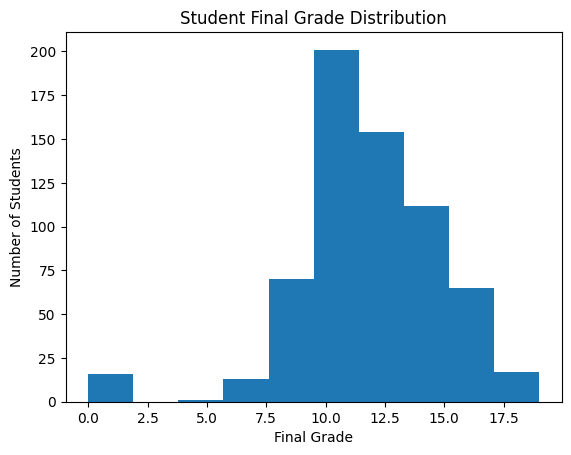

In [8]:
plt.hist(df["G3"])

plt.title("Student Final Grade Distribution")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.show()

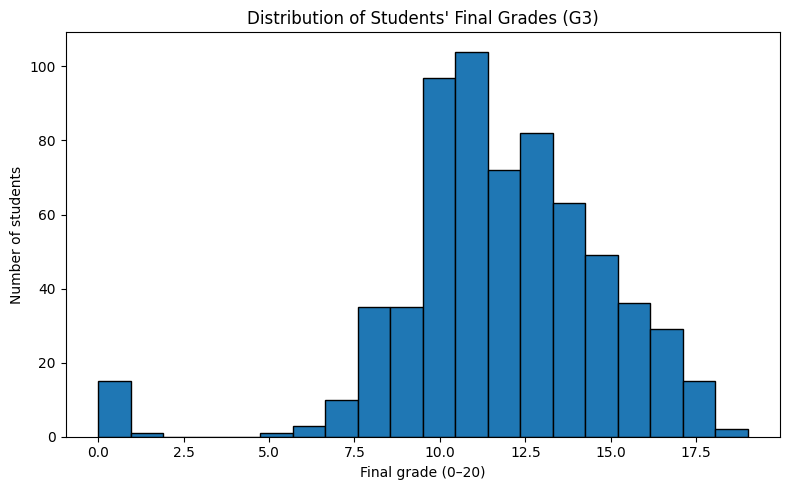

In [9]:
# 1. Distribution of final grades
plt.figure(figsize=(8, 5))
plt.hist(df["G3"], bins=20, edgecolor="black")
plt.title("Distribution of Students' Final Grades (G3)")
plt.xlabel("Final grade (0–20)")
plt.ylabel("Number of students")
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, "01_grade_distribution.png"), dpi=150)
plt.show()

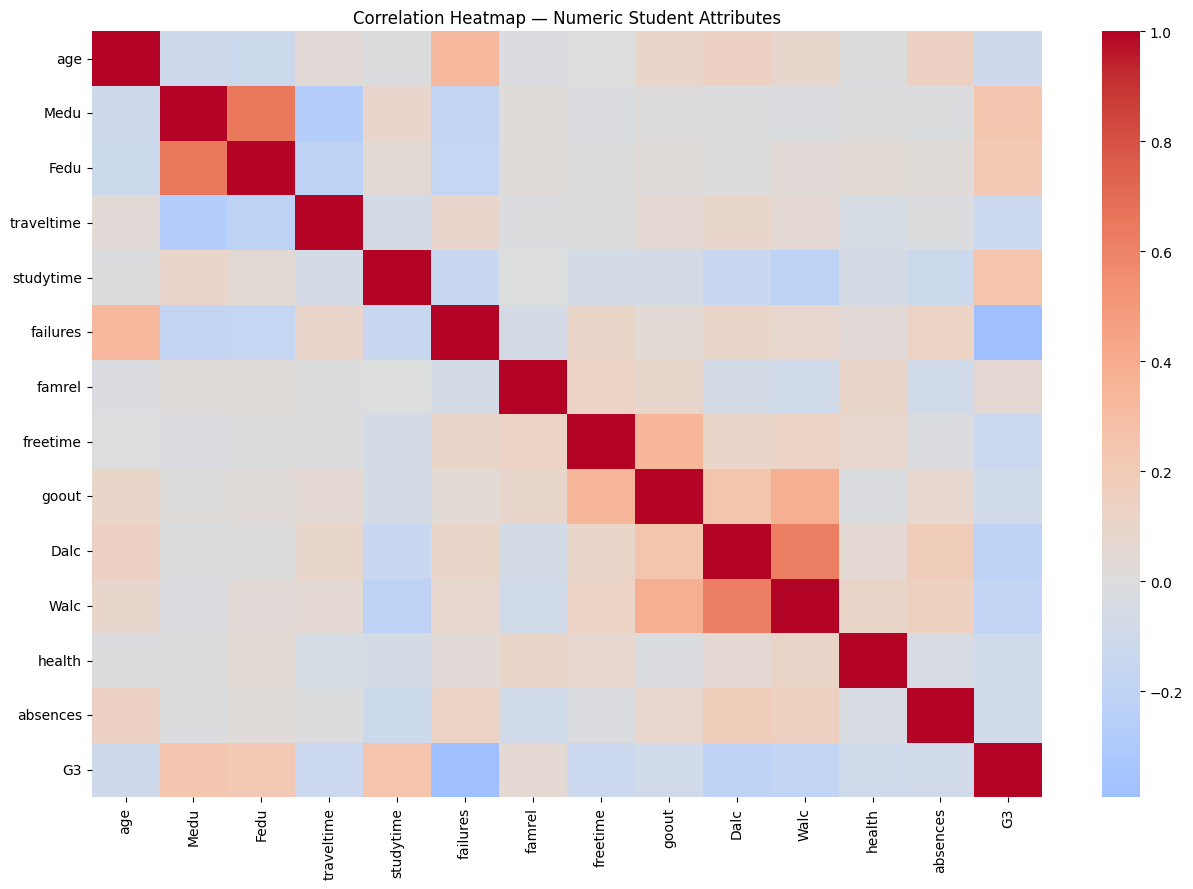

In [10]:
# 4. Correlation heatmap for numeric columns
numeric_df = df.select_dtypes(include=np.number)
plt.figure(figsize=(13, 9))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap — Numeric Student Attributes")
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, "04_correlation_heatmap.png"), dpi=150)
plt.show()

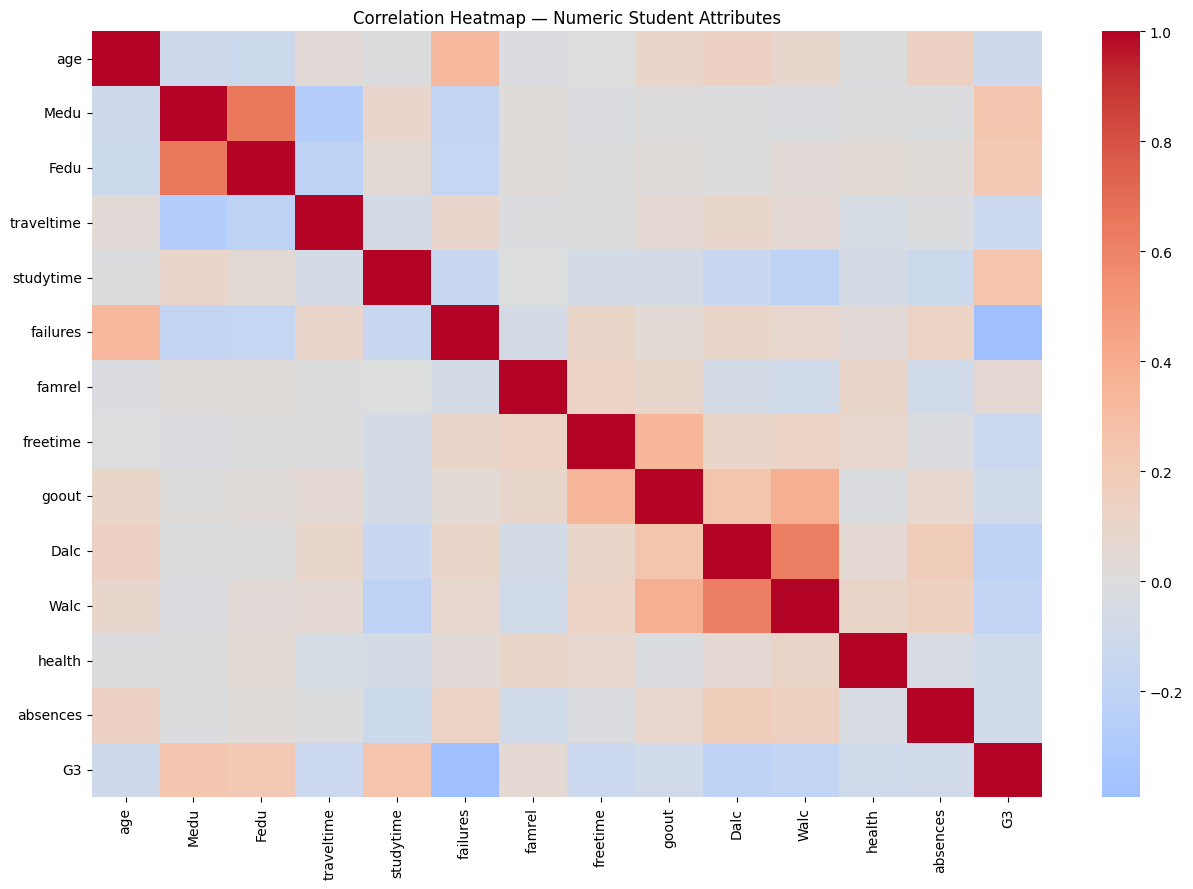

In [11]:
# 4. Correlation heatmap for numeric columns
numeric_df = df.select_dtypes(include=np.number)
plt.figure(figsize=(13, 9))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap — Numeric Student Attributes")
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, "04_correlation_heatmap.png"), dpi=150)
plt.show()

In [12]:
# Simple EDA observations to help write your report.
print("Average final grade:", round(df["G3"].mean(), 2))
print("Median final grade:", round(df["G3"].median(), 2))
print("Average absences:", round(df["absences"].mean(), 2))
print("\\nAverage grade by study-time category:")
display(df.groupby("studytime")["G3"].agg(["count", "mean", "median"]).round(2))
print("\\nAverage grade by number of past failures:")
display(df.groupby("failures")["G3"].agg(["count", "mean"]).round(2))

Average final grade: 11.91
Median final grade: 12.0
Average absences: 3.66
\nAverage grade by study-time category:


,count,mean,median
studytime,,,
1,212,10.84,11.0
2,305,12.09,12.0
3,97,13.23,13.0
4,35,13.06,13.0


\nAverage grade by number of past failures:


,count,mean
failures,,
0,549,12.51
1,70,8.64
2,16,8.81
3,14,8.07
